<a href="https://www.kaggle.com/code/nayonahmedlol/sdxl-image-generation?scriptVersionId=363569473" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# SDXL Image Generation

Generate images with Stable Diffusion XL using a reusable system instruction and user prompt.

In [1]:
!pip -q install diffusers transformers accelerate safetensors

In [2]:
import torch
from diffusers import StableDiffusionXLPipeline
from IPython.display import display

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=dtype,
    use_safetensors=True
).to(device)

model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(


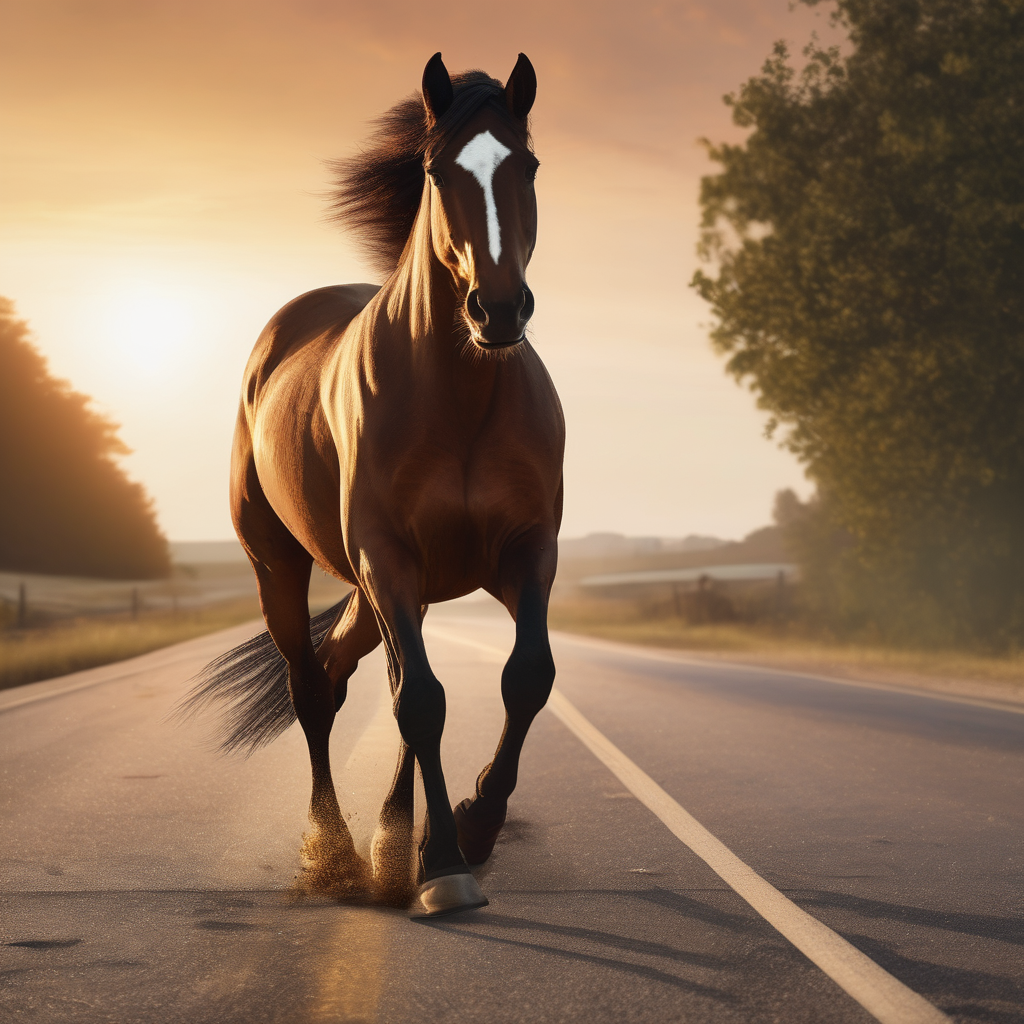

In [4]:
SYSTEM_PROMPT = "Create a high-quality, photorealistic image with detailed lighting, composition, textures, and natural colors."
USER_INPUT = "A horse running on a highway at sunset"

prompt = f"{SYSTEM_PROMPT} {USER_INPUT}"
image = pipe(prompt=prompt).images[0]
display(image)

In [5]:
image.save("generated_image.png")